# Лабораторная работа № 3 — Вариант 6
## JSONPlaceholder + REST Countries (основные) → World Bank API (обогащение)

**Вариант 6:** JSONPlaceholder + REST Countries; обогащение — World Bank API.

In [1]:
!pip install -q requests pandas matplotlib python-dotenv

^C


You should consider upgrading via the 'C:\Users\User\Documents\Yandex.Disk\Магистратура\2 курс\DataMining\venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [2]:
import requests, time, json, random, os
import pandas as pd
from datetime import datetime, timezone
from pathlib import Path
from dotenv import load_dotenv

load_dotenv()

PAGE_SIZE, MAX_RECORDS, MAX_PAGES = 100, 300, 10
DELAY, MAX_RETRIES, TIMEOUT = 0.5, 3, 20

RESTCOUNTRIES_KEY = os.getenv("RESTCOUNTRIES_KEY")

OUT = Path("");

s = requests.Session()
s.headers.update({
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                  "AppleWebKit/537.36 (KHTML, like Gecko) "
                  "Chrome/120.0.0.0 Safari/537.36",
    "Accept": "application/json, text/plain, */*",
    "Accept-Language": "en-US,en;q=0.9",
})

print(f"OUT = {OUT.resolve()}")

OUT = C:\Users\User\Documents\Yandex.Disk\Магистратура\2 курс\DataMining\lab_3


In [3]:
def get_json(url, params=None, headers=None, retry=0):
    try:
        r = s.get(url, params=params, headers=headers, timeout=TIMEOUT)
    except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as e:
        if retry >= MAX_RETRIES:
            raise RuntimeError(f"Сетевая ошибка после {MAX_RETRIES} попыток: {e}")
        time.sleep((2 ** retry) * random.uniform(1, 2))
        return get_json(url, params, headers, retry + 1)

    if r.status_code == 200:
        ct = r.headers.get("Content-Type", "").lower()
        if "json" not in ct:
            raise ValueError(f"Не JSON ({ct}): {r.text[:200]}")
        return r.json()

    if r.status_code == 429 or 500 <= r.status_code < 600:
        if retry >= MAX_RETRIES:
            raise RuntimeError(f"{r.status_code} после {MAX_RETRIES} попыток")
        ra = r.headers.get("Retry-After")
        wait = float(ra) if (ra and ra.replace('.', '', 1).isdigit()) else (2 ** retry) * random.uniform(1, 2)
        time.sleep(wait)
        return get_json(url, params, headers, retry + 1)

    raise RuntimeError(f"{r.status_code}: {r.text[:200]}")

In [4]:
log = []

def paginate(url, params_fn, extract=lambda d: d, max_pages=MAX_PAGES, headers=None):
    data, page = [], 1
    while page <= max_pages:
        params = params_fn(page)
        t0 = time.time()
        try:
            raw = get_json(url, params, headers=headers)
            chunk = extract(raw) if raw else []
            log.append({
                "page": page, "url": url, "status": 200,
                "records": len(chunk),
                "duration_sec": round(time.time() - t0, 3),
                "timestamp": datetime.now(timezone.utc).isoformat()
            })
            if not chunk:
                break
            data.extend(chunk)
            page += 1
            time.sleep(DELAY)
        except Exception as e:
            log.append({
                "page": page, "url": url, "status": 0, "records": 0,
                "duration_sec": round(time.time() - t0, 3),
                "timestamp": datetime.now(timezone.utc).isoformat(),
                "error": str(e)
            })
            print(f"Ошибка на стр. {page}: {e}")
            break
    return data

In [5]:
print("JSONPlaceholder: posts + comments")
posts_raw = paginate(
    "https://jsonplaceholder.typicode.com/posts",
    lambda p: {"_page": p, "_limit": PAGE_SIZE}
)
comments_raw = paginate(
    "https://jsonplaceholder.typicode.com/comments",
    lambda p: {"_page": p, "_limit": PAGE_SIZE}
)

posts = posts_raw[:MAX_RECORDS]
print(f"  posts: {len(posts_raw)}, comments: {len(comments_raw)}, итого posts (обрезка): {len(posts)}")

JSONPlaceholder: posts + comments
  posts: 100, comments: 500, итого posts (обрезка): 100


In [6]:
print("REST Countries")
countries = paginate(
    "https://api.restcountries.com/countries/v5",
    lambda p: {
        "limit": 100,
        "offset": (p - 1) * 100,
        "response_fields": "names.common,codes.alpha_2,codes.alpha_3,capitals,region,subregion,population,area,languages,currencies,borders,timezones"
    },
    extract=lambda d: d.get("data", {}).get("objects", []) if isinstance(d, dict) else [],
    max_pages=3,
    headers={"Authorization": f"Bearer {RESTCOUNTRIES_KEY}"}
)
print(f"  countries: {len(countries)}")

REST Countries
  countries: 254


In [7]:
print("📥 World Bank")

wb = []
page = 1
while True:
    raw = get_json(
        f"https://api.worldbank.org/v2/country/all/indicator/NY.GDP.MKTP.CD",
        {"format": "json", "date": "2022", "per_page": 1000, "page": page}
    )
    if not (isinstance(raw, list) and len(raw) > 1 and isinstance(raw[1], list) and raw[1]):
        break
    wb.extend(raw[1])
    meta = raw[0]
    print(f"стр. {page}/{meta.get('pages', 1)}: +{len(raw[1])}, всего {len(wb)}")
    if page >= meta.get("pages", 1):
        break
    page += 1
    time.sleep(1.5)

print(f"WB всего: {len(wb)}")

📥 World Bank
стр. 1/1: +266, всего 266
WB всего: 266


In [8]:
raw = OUT / "data_raw.jsonl"
with open(raw, "w", encoding="utf-8") as f:
    for src, recs in [("posts", posts), ("comments", comments_raw),
                      ("countries", countries), ("worldbank", wb)]:
        for r in recs:
            r["_source"] = src
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
print(f"{raw} ({raw.stat().st_size} байт)")

data_raw.jsonl (479954 байт)


In [9]:
pd.DataFrame(log).to_csv(OUT / "collection_log.csv", index=False, encoding="utf-8")
print(f"collection_log.csv ({len(log)} записей)")
pd.DataFrame(log)

collection_log.csv (11 записей)


,page,url,status,records,duration_sec,timestamp
0,1,https://jsonplaceholder.typicode.com/posts,200,100,0.454,2026-10-13T15:55:39.047258+00:00
1,2,https://jsonplaceholder.typicode.com/posts,200,0,0.624,2026-10-13T15:55:40.177041+00:00
2,1,https://jsonplaceholder.typicode.com/comments,200,100,0.304,2026-10-13T15:55:40.481149+00:00
3,2,https://jsonplaceholder.typicode.com/comments,200,100,0.303,2026-10-13T15:55:41.289454+00:00
4,3,https://jsonplaceholder.typicode.com/comments,200,100,0.233,2026-10-13T15:55:42.025689+00:00
5,4,https://jsonplaceholder.typicode.com/comments,200,100,0.233,2026-10-13T15:55:42.766699+00:00
6,5,https://jsonplaceholder.typicode.com/comments,200,100,0.249,2026-10-13T15:55:43.527144+00:00
7,6,https://jsonplaceholder.typicode.com/comments,200,0,0.234,2026-10-13T15:55:44.262374+00:00
8,1,https://api.restcountries.com/countries/v5,200,100,1.792,2026-10-13T15:55:46.549228+00:00
9,2,https://api.restcountries.com/countries/v5,200,100,1.250,2026-10-13T15:55:48.302196+00:00


In [10]:
import pandas as pd

rows = []
for c in countries:
    codes   = c.get("codes", {}) if isinstance(c.get("codes"), dict) else {}
    names   = c.get("names", {}) if isinstance(c.get("names"), dict) else {}
    capitals = c.get("capitals", []) if isinstance(c.get("capitals"), list) else []
    langs   = c.get("languages", []) if isinstance(c.get("languages"), list) else []
    currs   = c.get("currencies", []) if isinstance(c.get("currencies"), list) else []

    rows.append({
        "cca3": codes.get("alpha_3"),
        "cca2": codes.get("alpha_2"),
        "name_common": names.get("common"),
        "capital": capitals[0].get("name") if capitals else None,
        "region": c.get("region"),
        "subregion": c.get("subregion"),
        "population": c.get("population"),
        "area": (c.get("area", {}).get("kilometers")
                 if isinstance(c.get("area"), dict) else c.get("area")),
        "languages": "; ".join(l.get("name", str(l)) for l in langs) if langs else None,
        "currencies": "; ".join(
            f"{x.get('code')} ({x.get('name')})" if isinstance(x, dict) else str(x)
            for x in currs
        ) if currs else None,
        "borders": ", ".join(c.get("borders", [])) if isinstance(c.get("borders"), list) else None,
    })

df_countries = pd.DataFrame(rows)
df_countries = df_countries[df_countries["cca3"].notna() & (df_countries["cca3"] != "")]
print(f"countries: {df_countries.shape}")
df_countries.head()

countries: (250, 11)


,cca3,cca2,name_common,capital,region,subregion,population,area,languages,currencies,borders
1,AFG,AF,Afghanistan,Kabul,Asia,Southern Asia,43844000,652230.0,Dari; Pashto; Turkmen,AFN (Afghan afghani),"IRN, PAK, TKM, UZB, TJK, CHN"
2,ALB,AL,Albania,Tirana,Europe,Southeast Europe,2335930,28748.0,Albanian,ALL (Albanian lek),"MNE, GRC, MKD, UNK"
3,DZA,DZ,Algeria,Algiers,Africa,Northern Africa,47400000,2381741.0,Arabic,DZD (Algerian dinar),"TUN, LBY, NER, ESH, MRT, MLI, MAR"
4,ASM,AS,American Samoa,Pago Pago,Oceania,Polynesia,43268,199.0,English; Samoan,USD (United States dollar),
5,AND,AD,Andorra,Andorra la Vella,Europe,Southern Europe,90105,468.0,Catalan,EUR (Euro),"FRA, ESP"


In [11]:
# Развёртывание языков через record_path + meta
langs = pd.json_normalize(
    countries,
    record_path=["languages"],
    meta=["codes", "names", "population"],
    errors="ignore"
)
langs["cca3"] = langs["codes"].apply(lambda x: x.get("alpha_3") if isinstance(x, dict) else None)
langs["name_common"] = langs["names"].apply(lambda x: x.get("common") if isinstance(x, dict) else None)
langs = langs[["cca3", "name_common", "population", "name", "native_name"]]
langs.to_csv(OUT / "languages.csv", index=False, encoding="utf-8")
print(f"🌐 languages (record_path+meta): {langs.shape}")

# Аналогично — валюты (вложенный массив)
currs = pd.json_normalize(
    countries,
    record_path=["currencies"],
    meta=["codes", "names"],
    errors="ignore"
)
currs["cca3"] = currs["codes"].apply(lambda x: x.get("alpha_3") if isinstance(x, dict) else None)
currs = currs[["cca3", "code", "name", "symbol"]]
currs.to_csv(OUT / "currencies.csv", index=False, encoding="utf-8")
print(f"💰 currencies (record_path+meta): {currs.shape}")

🌐 languages (record_path+meta): (425, 5)
💰 currencies (record_path+meta): (272, 4)


In [12]:
# Нормализация WB
wb_df = pd.DataFrame([{
    "country_id": r.get("countryiso3code"),
    "indicator_id": r.get("indicator", {}).get("id"),
    "date": r.get("date"),
    "value": r.get("value")
} for r in wb])

wb_pivot = wb_df.pivot_table(
    index=["country_id", "date"], columns="indicator_id",
    values="value", aggfunc="first"
).reset_index().rename(columns={"NY.GDP.MKTP.CD": "gdp_usd"})
wb_pivot["date_int"] = pd.to_numeric(wb_pivot["date"], errors="coerce")
wb_latest = (wb_pivot.sort_values("date_int", ascending=False)
                     .drop_duplicates("country_id")
                     .drop(columns="date_int"))

# Merge
rows_before = len(df_countries)
df_countries["cca3"] = df_countries["cca3"].str.upper()
wb_latest["country_id"] = wb_latest["country_id"].str.upper()
merged = df_countries.merge(
    wb_latest, left_on="cca3", right_on="country_id", how="left"
).drop(columns="country_id", errors="ignore")
rows_after = len(merged)
print(f"🔗 merge: до={rows_before}, после={rows_after}, сохранено={rows_before == rows_after}")

🔗 merge: до=250, после=250, сохранено=True


In [13]:
# Даты
if "date" in merged.columns:
    merged["date"] = pd.to_datetime(merged["date"], format="%Y", utc=True, errors="coerce")

# Числа
for col in ["population", "area", "gdp_usd"]:
    if col in merged.columns:
        merged[col] = pd.to_numeric(merged[col], errors="coerce")

merged.dtypes

cca3                        object
cca2                        object
name_common                 object
capital                     object
region                      object
subregion                   object
population                   int64
area                       float64
languages                   object
currencies                  object
borders                     object
date           datetime64[ns, UTC]
gdp_usd                    float64
dtype: object

In [14]:
print("Полнота полей (%):")
for c in merged.columns:
    print(f"  {c:20s}: {merged[c].notna().mean()*100:6.1f}%")

print(f"\nДубликаты cca3: {merged['cca3'].duplicated().sum()}")

# Проверки бизнес-логики
errors = 0
if "population" in merged.columns:
    bad = (merged["population"].dropna() < 0).sum()
    print(f"population <= 0: {bad}")
    errors += bad
if "gdp_usd" in merged.columns:
    bad = (merged["gdp_usd"].dropna() <= 0).sum()
    print(f"gdp_usd <= 0: {bad}")
    errors += bad
if "area" in merged.columns:
    bad = (merged["area"].dropna() < 0).sum()
    print(f"area < 0: {bad}")
    errors += bad
if "date" in merged.columns:
    current_year = datetime.now(timezone.utc).year
    bad = (merged["date"].dt.year > current_year).sum()
    print(f"date.year > {current_year}: {bad}")
    errors += bad
print(f"\nПроверок бизнес-логики: 4, нарушений: {errors}")

Полнота полей (%):
  cca3                :  100.0%
  cca2                :  100.0%
  name_common         :  100.0%
  capital             :   98.0%
  region              :  100.0%
  subregion           :  100.0%
  population          :  100.0%
  area                :  100.0%
  languages           :   99.6%
  currencies          :   98.8%
  borders             :  100.0%
  date                :   82.8%
  gdp_usd             :   82.8%

Дубликаты cca3: 0
population <= 0: 0
gdp_usd <= 0: 0
area < 0: 0
date.year > 2026: 0

Проверок бизнес-логики: 4, нарушений: 0


In [15]:
sf = OUT / "state.json"
state = json.loads(sf.read_text()) if sf.exists() else {"known_ids": []}
known = set(state.get("known_ids", []))

new_posts = [p for p in posts if p.get("id") not in known]
print(f"Всего постов: {len(posts)}, новых: {len(new_posts)}")

# Обновляем состояние
state["known_ids"] = list(known | {p["id"] for p in posts if "id" in p})[:5000]
state["last_run"] = datetime.now(timezone.utc).isoformat()
sf.write_text(json.dumps(state, ensure_ascii=False, indent=2))
print(f"state.json (known_ids: {len(state['known_ids'])})")

Всего постов: 100, новых: 0
state.json (known_ids: 100)


In [16]:
final_cols = ["cca3", "cca2", "name_common", "region", "subregion",
              "capital", "population", "area", "gdp_usd", "date"]
final_cols = [c for c in final_cols if c in merged.columns]
clean = (merged[final_cols]
         .drop_duplicates("cca3")
         .sort_values("cca3")
         .reset_index(drop=True))
clean.to_csv(OUT / "data_clean.csv", index=False, encoding="utf-8")
print(f"data_clean.csv: {clean.shape}")
clean.head(10)

data_clean.csv: (250, 10)


,cca3,cca2,name_common,region,subregion,capital,population,area,gdp_usd,date
0,ABW,AW,Aruba,Americas,Caribbean,Oranjestad,110625,180.0,3.326671e+09,2022-01-01 00:00:00+00:00
1,AFG,AF,Afghanistan,Asia,Southern Asia,Kabul,43844000,652230.0,1.449724e+10,2022-01-01 00:00:00+00:00
2,AGO,AO,Angola,Africa,Middle Africa,Luanda,38778554,1246700.0,1.282340e+11,2022-01-01 00:00:00+00:00
3,AIA,AI,Anguilla,Americas,Caribbean,The Valley,16010,91.0,NaN,NaT
4,ALA,AX,Åland Islands,Europe,Northern Europe,Mariehamn,30654,1580.0,NaN,NaT
5,ALB,AL,Albania,Europe,Southeast Europe,Tirana,2335930,28748.0,1.901725e+10,2022-01-01 00:00:00+00:00
6,AND,AD,Andorra,Europe,Southern Europe,Andorra la Vella,90105,468.0,3.380613e+09,2022-01-01 00:00:00+00:00
7,ARE,AE,United Arab Emirates,Asia,Western Asia,Abu Dhabi,11027129,83600.0,5.114034e+11,2022-01-01 00:00:00+00:00
8,ARG,AR,Argentina,Americas,South America,Buenos Aires,46466688,2780400.0,6.339938e+11,2022-01-01 00:00:00+00:00
9,ARM,AM,Armenia,Asia,Western Asia,Yerevan,3103900,29743.0,1.951351e+10,2022-01-01 00:00:00+00:00


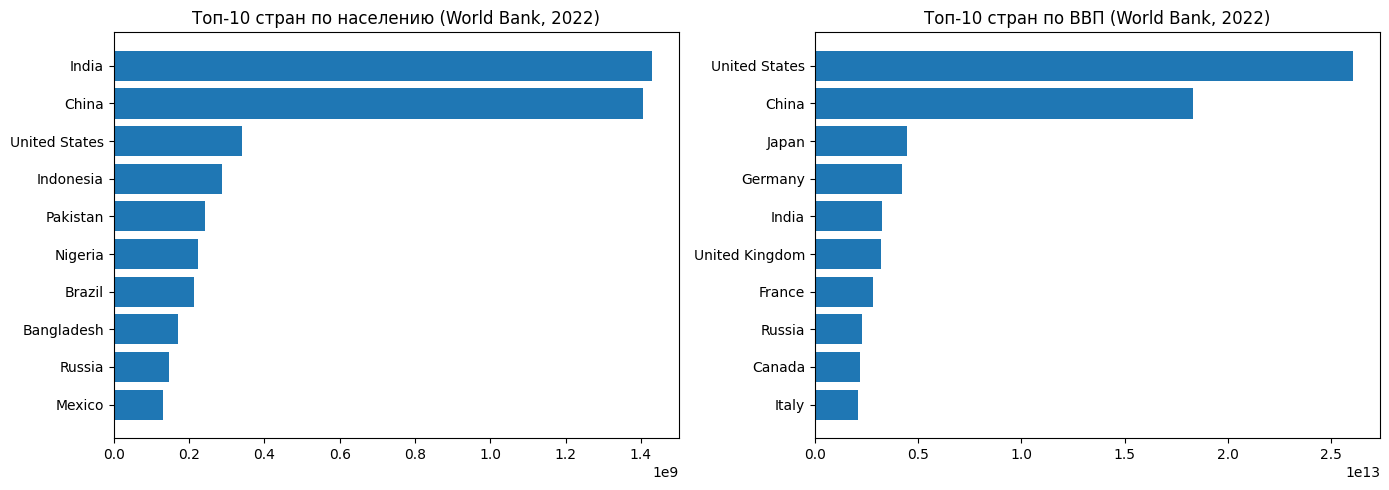

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

top_pop = clean.dropna(subset=["population"]).nlargest(10, "population")
if not top_pop.empty:
    ax[0].barh(top_pop["name_common"], top_pop["population"])
    ax[0].set_title("Топ-10 стран по населению (World Bank, 2022)")
    ax[0].invert_yaxis()

top_gdp = clean.dropna(subset=["gdp_usd"]).nlargest(10, "gdp_usd")
if not top_gdp.empty:
    ax[1].barh(top_gdp["name_common"], top_gdp["gdp_usd"])
    ax[1].set_title("Топ-10 стран по ВВП (World Bank, 2022)")
    ax[1].invert_yaxis()

plt.tight_layout()
plt.savefig(OUT / "top10.png", dpi=100)
plt.show()